# **4. Exploratory Component: The Cost of Hoarding**

**Research question:** How much revenue and charging capacity is the company losing due to hoarding, and can we predict at plug-in which sessions will hoard, so that a targeted idle fee can discourage it?

## 4.1. Preparing the data

Libraries for data handling and plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

Cleaned sessions from the pre-processing notebook (Section 1.5).

In [2]:
ev = pd.read_pickle("Data/ev_clean.pkl")
print(ev.shape)
# first rows of the main columns
ev[["station", "start", "end", "total_hours", "charging_hours", "idle_hours", "energy_kwh", "fee", "user_id"]].head()

(245736, 27)


,station,start,end,total_hours,charging_hours,idle_hours,energy_kwh,fee,user_id
0,PALO ALTO CA / HAMILTON #1,2011-07-29 20:17:00,2011-07-29 23:20:32,3.058889,1.900833,1.158056,6.249457,0.0,3284
1,PALO ALTO CA / HAMILTON #1,2011-07-30 00:00:00,2011-07-30 00:02:06,0.035000,0.031667,0.003333,0.106588,0.0,4169
2,PALO ALTO CA / HAMILTON #1,2011-07-30 08:16:00,2011-07-30 12:33:32,4.292222,4.291111,0.001111,14.951777,0.0,4169
3,PALO ALTO CA / HAMILTON #1,2011-07-30 14:51:00,2011-07-30 16:54:24,2.056667,2.049444,0.007222,7.159643,0.0,2545
4,PALO ALTO CA / HAMILTON #1,2011-07-30 18:51:00,2011-07-30 20:02:24,1.190000,0.731667,0.458333,1.957765,0.0,3765


A session counts as hoarding when the car stays plugged in for more than one hour after charging has finished. We also keep a two-hour version to check later whether the conclusions depend on this threshold.

In [3]:
HOARD_THRESHOLD = 1  # hours of idle time

ev["hoarding"] = (ev["idle_hours"] > HOARD_THRESHOLD).astype(int) # > 1 hour of idle = hoarding
ev["hoarding_2h"] = (ev["idle_hours"] > 2).astype(int) # 2 hours of idle

print(f"Hoarding sessions (> 1 h idle): {ev['hoarding'].sum():,} ({ev['hoarding'].mean() * 100:.1f}%)")
print(f"Hoarding sessions (> 2 h idle): {ev['hoarding_2h'].sum():,} ({ev['hoarding_2h'].mean() * 100:.1f}%)")

Hoarding sessions (> 1 h idle): 30,409 (12.4%)
Hoarding sessions (> 2 h idle): 14,868 (6.1%)


Checks: idle time should never be negative after cleaning, and the target must have no missing values.

In [4]:
# idle time and target checks
print("Negative idle time:", (ev["idle_hours"] < 0).sum())
print("Missing idle time:", ev["idle_hours"].isna().sum())
print("Missing target:", ev["hoarding"].isna().sum())
ev["idle_hours"].describe().round(2)

Negative idle time: 0
Missing idle time: 0
Missing target: 0


count    245736.00
mean          0.50
std           1.40
min           0.00
25%           0.00
50%           0.01
75%           0.37
max          22.40
Name: idle_hours, dtype: float64

## 4.2. Describing the problem

Share of hoarding sessions by the hour the car is plugged in.

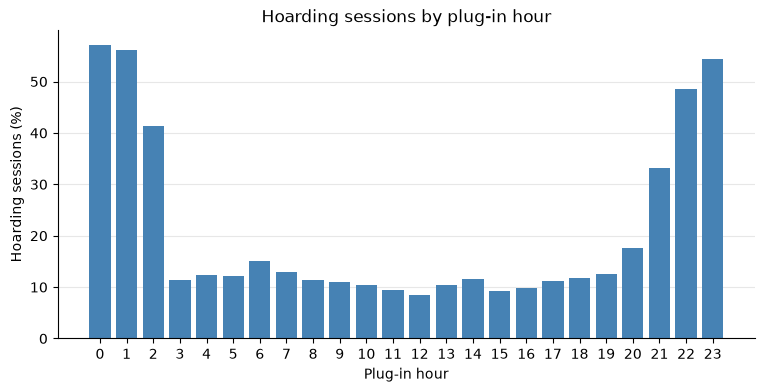

In [5]:
# start hour of the session
ev["start_hour"] = ev["start"].dt.hour  

# percentage of hoarding sessions by hour
by_hour = ev.groupby("start_hour")["hoarding"].mean() * 100 

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.values, color="steelblue")
ax.set_title("Hoarding sessions by plug-in hour")
ax.set_xlabel("Plug-in hour")
ax.set_ylabel("Hoarding sessions (%)")
ax.set_xticks(range(0, 24))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Share of hoarding sessions by station.

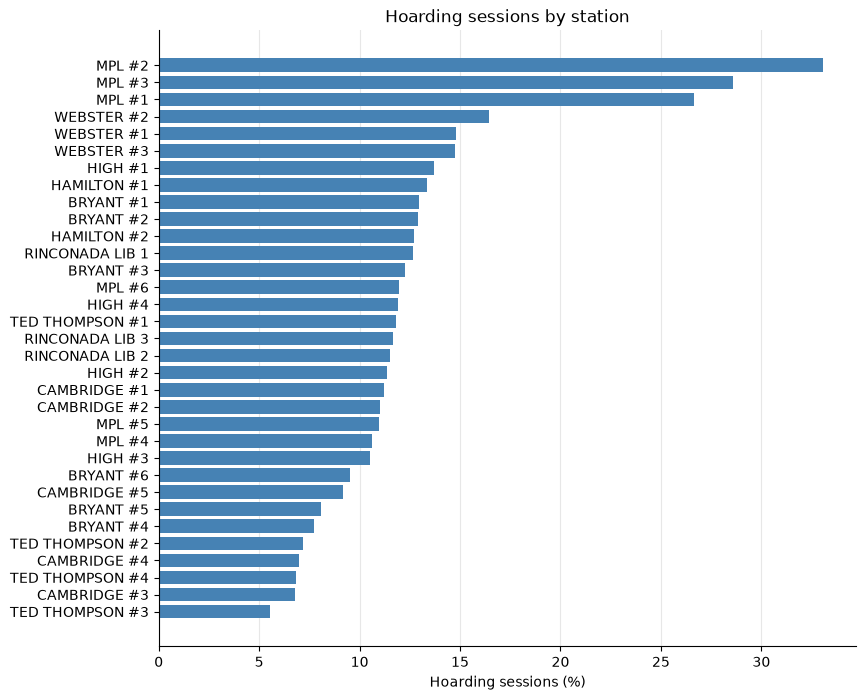

In [6]:
# percentage of hoarding sessions by station
by_station = (ev.groupby("station", observed=True)["hoarding"].mean() * 100).sort_values() 

# remove the "PALO ALTO CA / " prefix from the names
by_station.index = by_station.index.str.replace("PALO ALTO CA / ", "") 

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(by_station.index, by_station.values, color="steelblue")
ax.set_title("Hoarding sessions by station")
ax.set_xlabel("Hoarding sessions (%)")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.show()

Charger hours blocked by hoarding each year. Idle time counts as daytime when charging finishes between 07:00 and 22:00, the hours when other drivers are most likely to need the charger.

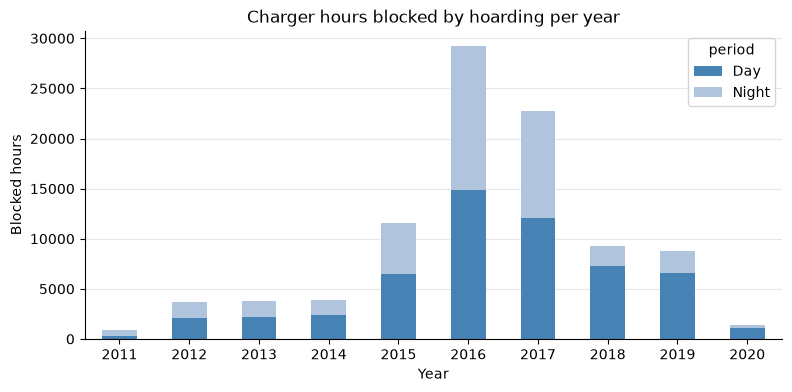

period      Day    Night
start                   
2011      324.0    557.0
2012     2130.0   1574.0
2013     2178.0   1572.0
2014     2379.0   1531.0
2015     6493.0   5094.0
2016    14860.0  14411.0
2017    12053.0  10710.0
2018     7302.0   1963.0
2019     6606.0   2214.0
2020     1079.0    358.0


In [7]:
# hour when the idle period starts
ev["idle_start_hour"] = (ev["start"] + pd.to_timedelta(ev["charging_hours"], unit="h")).dt.hour 

# daytime = 7-21, nighttime = 22-6
ev["period"] = np.where(ev["idle_start_hour"].between(7, 21), "Day", "Night") 

# blocked hours by hoarding per year
blocked = (ev[ev["hoarding"] == 1]
           .groupby([ev["start"].dt.year, "period"])["idle_hours"].sum()
           .unstack())

fig, ax = plt.subplots(figsize=(9, 4))
blocked.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "lightsteelblue"])
ax.set_title("Charger hours blocked by hoarding per year")
ax.set_xlabel("Year")
ax.set_ylabel("Blocked hours")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(blocked.round(0))

Daytime charger hours blocked by hoarding per year at each station (top 10). We use only 2018 and 2019, so stations that opened earlier do not score higher just because they have more years of data. In those two years all 33 stations were open by March 2018 and 99.8% of sessions were paid. The 146 unpaid sessions are spread over many stations and months, and half of them lasted under three minutes, so they look like aborted or test plug-ins rather than a free tariff. Six stations opened in March 2018 and have about 22 months of data instead of 24, so their hours per year are slightly underestimated. Correcting for this does not change the top four.

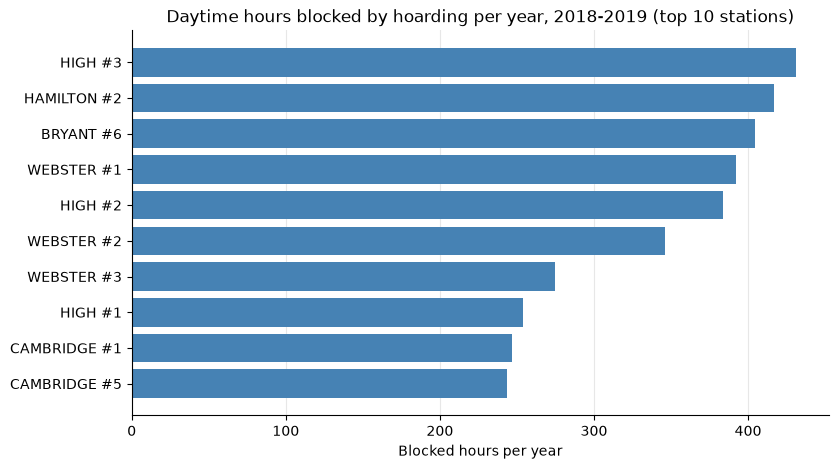

station
HIGH #3         431.0
HAMILTON #2     417.0
BRYANT #6       404.0
WEBSTER #1      392.0
HIGH #2         384.0
WEBSTER #2      346.0
WEBSTER #3      275.0
HIGH #1         254.0
CAMBRIDGE #1    247.0
CAMBRIDGE #5    244.0
Name: idle_hours, dtype: float64


In [8]:
# only 2018 and 2019: full years with all stations open (the data end in February 2020)
recent = ev[ev["start"].dt.year.isin([2018, 2019])] 

day_blocked = (recent[(recent["hoarding"] == 1) & (recent["period"] == "Day")]
               .groupby("station", observed=True)["idle_hours"].sum() / 2  # two years, so hours per year
               ).sort_values().tail(10)
day_blocked.index = day_blocked.index.str.replace("PALO ALTO CA / ", "")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(day_blocked.index, day_blocked.values, color="steelblue")
ax.set_title("Daytime hours blocked by hoarding per year, 2018-2019 (top 10 stations)")
ax.set_xlabel("Blocked hours per year")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(day_blocked.round(0).sort_values(ascending=False))

**Key findings.** Most hoarding happens at night: about half of the sessions that start between 22:00 and 01:00 hoard, compared with about 10% of daytime sessions. Blocked hours peaked in 2016. From 2018, with nearly all sessions paid, night hoarding dropped sharply, but daytime hoarding stayed at about 7,000 hours a year.

MPL #1 to #3 have the highest hoarding rates (27 to 33%), but they are among the least used chargers, so their hoarding blocks few drivers. We therefore compare stations by the daytime hours they lose to hoarding each year in 2018 and 2019, when nearly all sessions were paid and all stations were open. On that measure the worst stations are HIGH #3, HAMILTON #2, BRYANT #6 and WEBSTER #1, with about 400 blocked hours a year each. Section 4.4 turns these blocked hours into an estimate of lost revenue.

## 4.3. Feature engineering

The analysis in 4.2 used the whole dataset because it is descriptive. From here on, every modelling decision (feature choice, fill values, model selection) uses the training data only.

**Driver history.** For each session we count the driver's earlier sessions and how many of them were hoarding. An earlier session only counts if it had already ended when the current one started, because before the car is unplugged we do not know whether it hoarded. The history is computed on the full dataset in time order, so test sessions see the history that would really have been known at that moment.

First we count how often a driver plugs in again before their previous session has ended, since these are the cases where the rule above matters. Comparing each session with the driver's previous one gives 739 cases; comparing it with any earlier session still in progress gives 750.

In [9]:
# sort by start time; kind="stable" keeps ties (same start) in the order of the original file.
# event_id is not used as a tie-breaker because it is not unique in this dataset.
ev = ev.sort_values("start", kind="stable").reset_index(drop=True)

# for each session, get the end time of the previous session for the same user
prev_end_same_user = ev.groupby("user_id")["end"].shift()
overlap = ev["user_id"].notna() & (ev["user_id"] != "0") & (prev_end_same_user > ev["start"])
print("Sessions that start before the driver's previous session ended:", overlap.sum())

# same check against any earlier session of the driver that was still in progress
latest_end_before = ev.groupby("user_id")["end"].transform(lambda s: s.cummax().shift())
overlap_any = ev["user_id"].notna() & (ev["user_id"] != "0") & (latest_end_before > ev["start"])
print("Sessions that start before any earlier session of the driver ended:", overlap_any.sum())

Sessions that start before the driver's previous session ended: 739


Sessions that start before any earlier session of the driver ended: 750


Computing the history. User ID 0 is a shared default account (it has overlapping sessions at different stations and no postal code), so it is treated as unknown and gets no history.

In [10]:
# user_id "0" is a shared default account (2011-2015), not one driver, so it gets no history
known_user = ev["user_id"].notna() & (ev["user_id"] != "0")

ev["prev_sessions"] = 0
ev["prev_hoardings"] = 0

for user, g in ev[known_user].groupby("user_id"):
    # earlier sessions sorted by the time they ended
    ends = g.sort_values("end")
    end_times = ends["end"].values
    hoard_cumsum = ends["hoarding"].cumsum().values

    # number of sessions that had ended by the time each session started
    n_done = np.searchsorted(end_times, g["start"].values, side="right")
    ev.loc[g.index, "prev_sessions"] = n_done
    ev.loc[g.index, "prev_hoardings"] = np.where(n_done > 0, hoard_cumsum[n_done - 1], 0)

ev["has_history"] = (ev["prev_sessions"] > 0).astype(int)
ev["prev_hoarding_rate"] = ev["prev_hoardings"] / ev["prev_sessions"].where(ev["prev_sessions"] > 0)

print(f"Sessions without history: {(ev['has_history'] == 0).mean() * 100:.1f}%")

Sessions without history: 11.5%


**Calendar and price features.** Seasons follow the usual meteorological months: winter (Dec, Jan, Feb), spring (Mar, Apr, May), summer (Jun, Jul, Aug) and autumn (Sep, Oct, Nov). `paid_period` is 1 from the first paid session onwards; it is known at plug-in and does not use the fee amount.

In [11]:
season_map = {12: "winter", 1: "winter", 2: "winter",
              3: "spring", 4: "spring", 5: "spring",
              6: "summer", 7: "summer", 8: "summer",
              9: "autumn", 10: "autumn", 11: "autumn"}

# start_hour was already created in 4.2
ev["day_of_week"] = ev["start"].dt.dayofweek
ev["is_weekend"] = (ev["day_of_week"] >= 5).astype(int)
ev["month"] = ev["start"].dt.month
ev["season"] = ev["month"].map(season_map)

first_paid = ev.loc[ev["fee"] > 0, "start"].min()
ev["paid_period"] = (ev["start"] >= first_paid).astype(int)
print("First paid session:", first_paid)

ev[["start", "station", "start_hour", "day_of_week", "is_weekend", "month", "season", "paid_period"]].head()

First paid session: 2017-08-01 05:16:00


,start,station,start_hour,day_of_week,is_weekend,month,season,paid_period
0,2011-07-29 20:17:00,PALO ALTO CA / HAMILTON #1,20,4,0,7,summer,0
1,2011-07-30 00:00:00,PALO ALTO CA / HAMILTON #1,0,5,1,7,summer,0
2,2011-07-30 08:16:00,PALO ALTO CA / HAMILTON #1,8,5,1,7,summer,0
3,2011-07-30 14:51:00,PALO ALTO CA / HAMILTON #1,14,5,1,7,summer,0
4,2011-07-30 18:51:00,PALO ALTO CA / HAMILTON #1,18,5,1,7,summer,0


**Train, validation and test split.** Sessions are split in time order without shuffling: the first 70% are the training data and the last 30% the test set. The last 20% of the training data are kept as a validation set to compare models, so the test set is only used once at the end.

Two scenarios are compared. In the main scenario (A) the split covers all sessions. In scenario B the same split is applied only to the paid period (from August 2017), so the model learns the behaviour that followed the introduction of fees. Driver history is the same in both, because it was computed on the full dataset.

In [12]:
def temporal_split(data, train_share=0.7, val_share=0.2):
    data = data.sort_values("start", kind="stable")  # ties keep the original file order
    n_train = int(len(data) * train_share)
    n_fit = int(n_train * (1 - val_share))
    return data.iloc[:n_fit], data.iloc[n_fit:n_train], data.iloc[n_train:]

fit_A, val_A, test_A = temporal_split(ev)
fit_B, val_B, test_B = temporal_split(ev[ev["paid_period"] == 1])

Summary of each set, kept for the report: it helps explain the test metrics, since the hoarding rate falls over time.

In [13]:
# one row per set: dates, number of sessions, hoarding rate and share of paid sessions
rows = []
for scenario, sets in [("A (all sessions)", [fit_A, val_A, test_A]),
                       ("B (paid period)", [fit_B, val_B, test_B])]:
    for name, d in zip(["fit", "validation", "test"], sets):
        rows.append({"scenario": scenario, "set": name,
                     "from": d["start"].min().date(), "to": d["start"].max().date(),
                     "sessions": len(d),
                     "hoarding (%)": round(d["hoarding"].mean() * 100, 1),
                     "paid period (%)": round(d["paid_period"].mean() * 100, 1)})

split_table = pd.DataFrame(rows)
split_table

,scenario,set,from,to,sessions,hoarding (%),paid period (%)
0,A (all sessions),fit,2011-07-29,2017-09-28,137612,15.5,4.7
1,A (all sessions),validation,2017-09-28,2018-07-31,34403,9.2,100.0
2,A (all sessions),test,2018-07-31,2020-02-29,73721,7.9,100.0
3,B (paid period),fit,2017-08-01,2019-02-12,64144,9.1,100.0
4,B (paid period),validation,2019-02-12,2019-06-16,16036,7.7,100.0
5,B (paid period),test,2019-06-16,2020-02-29,34364,7.2,100.0


**Season or month.** Season is a grouping of months, so at most one of the two is used. On the training data of scenario A (fit plus validation) we look at the hoarding rate by season separately for the free and the paid period. If the differences disappear within each period, the apparent seasonal effect came from the change in pricing over time.

In [14]:
# training data of scenario A (fit + validation), used for the checks below and for the final model
train_A = pd.concat([fit_A, val_A])

season_check = (train_A.groupby(["paid_period", "season"])["hoarding"]
                .agg(["mean", "size"])
                .rename(columns={"mean": "hoarding (%)", "size": "sessions"}))
season_check["hoarding (%)"] = (season_check["hoarding (%)"] * 100).round(1)
season_check.unstack(0)

hoarding (%)      sessions       
paid_period            0    1        0      1
season                                       
autumn              16.1  9.0    28219   9648
spring              15.8  8.8    37434  10991
summer              15.9  8.7    34115  10662
winter              15.9  9.7    31424   9522

**Decision.** Within each period the hoarding rate barely changes with the season (15.8 to 16.1% before fees, 8.7 to 9.7% after), while the two periods differ by about 7 points. Month is a finer version of the same information, so neither season nor month is used as a feature.

Hoarding rate by day of the week on the training data (scenario A, fit plus validation), used for the decision below.

In [15]:
dow_check = (train_A.groupby("day_of_week")["hoarding"].mean() * 100).round(1)
dow_check.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_check

Mon    14.1
Tue    14.5
Wed    14.6
Thu    14.4
Fri    14.5
Sat    13.8
Sun    13.7
Name: hoarding, dtype: float64

**Feature decisions.**

- Season and month are not used.
- From the day of the week only `is_weekend` is kept. On the training data the hoarding rate is 14.1 to 14.6% on weekdays and 13.7 to 13.8% at weekends, so the individual day adds nothing beyond weekday versus weekend.
- `month`, `season` and `day_of_week` were created only for these checks and are not used by the models.
- `station` is a category, not a number. Logistic regression and random forest get it one-hot encoded; gradient boosting uses it as a native categorical feature.
- `start_hour` is one-hot encoded for logistic regression, because hoarding is high at night and low during the day, and a single linear coefficient cannot follow that pattern. The tree models use it as a number.
- Base features: `start_hour`, `is_weekend`, `station`, `paid_period`. History features: `prev_sessions`, `prev_hoarding_rate`, `has_history`.
- Scenario B does not use `paid_period`, because every session in it is paid and the column is always 1.

Stations in the validation and test sets that never appear in the data used to train the model. For logistic regression and random forest the one-hot encoder ignores an unknown station, so the session is predicted from the other features only. Gradient boosting handles an unseen category itself, without a separate encoding step.

In [16]:
# check that the validation and test sets do not contain stations that were not in the training set
for scenario, train, val, test in [("A", fit_A, val_A, test_A), ("B", fit_B, val_B, test_B)]:
    seen_fit = set(train["station"])
    seen_final = seen_fit | set(val["station"])
    new_in_val = ~val["station"].isin(seen_fit)
    new_in_test = ~test["station"].isin(seen_final)
    print(f"Scenario {scenario}: validation sessions at stations not in fit: {new_in_val.sum()} "
          f"| test sessions at stations not in fit+val: {new_in_test.sum()}")

Scenario A: validation sessions at stations not in fit: 2285 | test sessions at stations not in fit+val: 0
Scenario B: validation sessions at stations not in fit: 0 | test sessions at stations not in fit+val: 0


**Filling missing driver history.** `prev_hoarding_rate` is missing for sessions without history. We fill it with the hoarding rate of the data the model is trained on, never with values from the set being evaluated. This happens twice: with the fit set when models are compared on the validation set, and with fit plus validation for the final model evaluated on the test set. Scenario B follows the same procedure with its own sets.

In [17]:
def fill_history(train, *others):
    fill_value = train["hoarding"].mean()
    filled = [d.assign(prev_hoarding_rate=d["prev_hoarding_rate"].fillna(fill_value))
              for d in (train, *others)]
    return fill_value, filled

# model selection: train on fit, evaluate on validation
fill_A, (fit_A_f, val_A_f) = fill_history(fit_A, val_A)

# final model: train on fit + validation, evaluate on test
fill_A_final, (train_A_f, test_A_f) = fill_history(train_A, test_A)

print(f"Fill value (fit): {fill_A:.3f} | fill value (fit + validation): {fill_A_final:.3f}")
print("Missing prev_hoarding_rate left:", test_A_f["prev_hoarding_rate"].isna().sum())

# scenario B, same procedure
fill_B, (fit_B_f, val_B_f) = fill_history(fit_B, val_B)
train_B = pd.concat([fit_B, val_B])
fill_B_final, (train_B_f, test_B_f) = fill_history(train_B, test_B)
print(f"Scenario B fill value (fit): {fill_B:.3f} | fill value (fit + validation): {fill_B_final:.3f}")

Fill value (fit): 0.155 | fill value (fit + validation): 0.143
Missing prev_hoarding_rate left: 0
Scenario B fill value (fit): 0.091 | fill value (fit + validation): 0.088


**Sanity checks** before modelling.

Every session must end after it starts; the history rule relies on it.

In [18]:
# count sessions where the end time is before or equal to the start time
print("Sessions with end <= start:", (ev["end"] <= ev["start"]).sum())

Sessions with end <= start: 0


Sessions of one driver who plugged in again before the previous session had ended. The session still in progress must not count in the history of the next one.

In [19]:
# check the sessions that start before the previous session ended for the same user
example_user = ev.loc[overlap, "user_id"].iloc[0]
example = ev.loc[ev["user_id"] == example_user,
                 ["start", "end", "hoarding", "prev_sessions", "prev_hoardings", "prev_hoarding_rate"]]

first_overlap = ev.index[overlap & (ev["user_id"] == example_user)][0]
pos = example.index.get_loc(first_overlap)
example.iloc[max(pos - 3, 0): pos + 3]

,start,end,hoarding,prev_sessions,prev_hoardings,prev_hoarding_rate
211,2011-09-14 19:45:00,2011-09-14 21:54:23,0,0,0,NaN
253,2011-09-20 21:10:00,2011-09-20 22:39:04,0,1,0,0.0
254,2011-09-20 22:39:00,2011-09-20 22:42:07,0,1,0,0.0
64981,2016-04-19 17:26:00,2016-04-19 20:00:42,1,3,0,0.0


Final feature lists. The check fails if any column that is only known after the session, or derived from the target, is used. Features are kept in two groups so the best model can be trained with and without driver history. This shows whether knowing the driver improves the prediction, or whether station and time of day are enough for the company to target an idle fee.

In [20]:
# final features for the model
BASE_FEATURES = ["start_hour", "is_weekend", "station", "paid_period"]
HISTORY_FEATURES = ["prev_sessions", "prev_hoarding_rate", "has_history"]
ALL_FEATURES = BASE_FEATURES + HISTORY_FEATURES

# columns only known when the session ends, or derived from the target
forbidden = {"total_hours", "charging_hours", "idle_hours", "energy_kwh", "fee", "end",
             "total_duration", "charging_time", "ghg_kg", "gasoline_gal", "ended_by",
             "end_tz", "transaction_date",
             "idle_start_hour", "period", "hoarding", "hoarding_2h", "prev_hoardings"}
assert not forbidden & set(ALL_FEATURES), forbidden & set(ALL_FEATURES)

print("Base features:", BASE_FEATURES)
print("History features:", HISTORY_FEATURES)

Base features: ['start_hour', 'is_weekend', 'station', 'paid_period']
History features: ['prev_sessions', 'prev_hoarding_rate', 'has_history']


Share of sessions without driver history in each set, and how many sessions have a very short history (1 to 4 earlier sessions), where the past hoarding rate is noisy.

In [21]:
# check the number of sessions without history and with 1-4 previous sessions in each set
for name, d in [("A fit", fit_A), ("A validation", val_A), ("A test", test_A),
                ("B fit", fit_B), ("B validation", val_B), ("B test", test_B)]:
    short = d["prev_sessions"].between(1, 4)
    print(f"{name:<13} without history: {(d['has_history'] == 0).mean() * 100:5.1f}% | "
          f"1-4 earlier sessions: {short.sum():,} ({short.mean() * 100:.1f}%)")

A fit         without history:  10.9% | 1-4 earlier sessions: 17,120 (12.4%)
A validation  without history:  11.5% | 1-4 earlier sessions: 4,912 (14.3%)
A test        without history:  12.6% | 1-4 earlier sessions: 10,300 (14.0%)
B fit         without history:  12.3% | 1-4 earlier sessions: 9,233 (14.4%)
B validation  without history:  11.9% | 1-4 earlier sessions: 2,143 (13.4%)
B test        without history:  12.6% | 1-4 earlier sessions: 4,828 (14.0%)
